# ShopperSense · 02 / Models and results

Run the training pipeline first: `python -m src.run_all`. This notebook imports the shared estimators, evaluation and selection functions, audits their saved evidence and explains results. It does **not** train an alternative model or tune from test outcomes. The pipeline trains all models; notebook execution is a separate verification gate.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'src').is_dir(), 'Start Jupyter from the repository root or notebooks/.'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, SVG
from src.data import load_data
from src.config import FEATURES, NUMERIC, CATEGORICAL
def saved(name):
    return json.loads((ROOT / 'results' / name).read_text(encoding='utf-8'))
raw, frame = load_data(ROOT / 'data/raw/online_shoppers_intention.csv')
splits = saved('splits.json')
train_ids = splits['partitions']['train']['source_row_ids']
train = frame.loc[train_ids]


## A baseline and three standard classifiers
Dummy always predicts the majority. Logistic Regression models a regularized linear log-odds boundary. A Decision Tree gives nonlinear rules but can overfit. A Random Forest averages randomized trees to reduce variance, with less direct interpretability. All learned models use bounded, training-only 3-fold stratified CV ranked by purchase average precision (AP).

In [2]:
from src.train import definitions
display(pd.DataFrame([{'model': name, 'estimator': str(estimator), 'grid': grid} for name, (estimator, grid) in definitions().items()]))
cv = pd.read_csv(ROOT / 'results/cv_results.csv')
display(cv[['model','feature_set','params','split0_test_score','split1_test_score','split2_test_score','mean_test_score','std_test_score','rank_test_score']])
assert not any(w['category'] == 'ConvergenceWarning' for w in saved('warnings.json'))

,model,estimator,grid
0,Dummy,"DummyClassifier(random_state=42, strategy='mos...",{}
1,Logistic Regression,"LogisticRegression(max_iter=2000, random_state...","{'model__C': ['0.1', 1, 10]}"
2,Decision Tree,DecisionTreeClassifier(random_state=42),"{'model__max_depth': [3, 5, 8], 'model__min_sa..."
3,Random Forest,"RandomForestClassifier(n_estimators=150, n_job...","{'model__max_depth': [8, None], 'model__min_sa..."


,model,feature_set,params,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score
0,Logistic Regression,full,{'model__C': 0.1},0.614988,0.660087,0.662694,0.645923,0.021900,1
1,Logistic Regression,full,{'model__C': 1},0.611831,0.655354,0.658545,0.641910,0.021309,2
2,Logistic Regression,full,{'model__C': 10},0.609469,0.654217,0.655981,0.639889,0.021522,3
3,Decision Tree,full,"{'model__max_depth': 3, 'model__min_samples_le...",0.617643,0.678041,0.634555,0.643413,0.025441,4
4,Decision Tree,full,"{'model__max_depth': 3, 'model__min_samples_le...",0.617643,0.678041,0.634555,0.643413,0.025441,4
5,Decision Tree,full,"{'model__max_depth': 5, 'model__min_samples_le...",0.663298,0.694351,0.683419,0.680356,0.012861,3
6,Decision Tree,full,"{'model__max_depth': 5, 'model__min_samples_le...",0.677387,0.722022,0.693742,0.697717,0.018438,1
7,Decision Tree,full,"{'model__max_depth': 8, 'model__min_samples_le...",0.619065,0.611430,0.603961,0.611485,0.006166,6
8,Decision Tree,full,"{'model__max_depth': 8, 'model__min_samples_le...",0.684408,0.717833,0.688942,0.697061,0.014804,2
9,Random Forest,full,"{'model__max_depth': 8, 'model__min_samples_le...",0.715713,0.757185,0.743534,0.738811,0.017257,2


## Validation chooses; test evaluates
Take the highest validation AP with a 0.005 practical tolerance favoring LR, then Tree, then Forest. Full features are primary. For the selected model maximize validation F1 on 0.05..0.95 in 0.01 steps; ties prefer the larger threshold. These functions have no test-data arguments. AP is not trapezoidal PR-AUC; scores are not claimed calibrated.

In [3]:
from src.evaluate import choose_model, choose_threshold, metrics
selection = saved('selection.json')
validation = pd.read_csv(ROOT / 'results/validation_metrics.csv')
display(validation)
assert choose_model(validation.to_dict('records')) == selection['selected_model']
predictions = pd.read_csv(ROOT / 'results/validation_predictions.csv')
selected_rows = predictions[(predictions.model == selection['selected_model']) & (predictions.feature_set == 'full')]
threshold, grid = choose_threshold(selected_rows.y_true, selected_rows.purchase_score)
assert threshold == selection['threshold']
display(pd.Series({k: selection[k] for k in ['selected_model','selected_parameters','threshold','model_rule','threshold_rule','frozen_at_utc','run_id']}))
display(pd.DataFrame(saved('events.json')))

,model,feature_set,partition,threshold,support,purchases,predicted_purchases,precision,recall,f1,ap,roc_auc,accuracy,tn,fp,fn,tp,precision_defined,recall_defined
0,Dummy,full,validation,0.5,1850,286,0,0.000000,0.000000,0.000000,0.154595,0.500000,0.845405,1564,0,286,0,False,True
1,Logistic Regression,full,validation,0.5,1850,286,139,0.733813,0.356643,0.480000,0.648512,0.893956,0.880541,1527,37,184,102,True,True
2,Decision Tree,full,validation,0.5,1850,286,195,0.738462,0.503497,0.598753,0.684044,0.912421,0.895676,1513,51,142,144,True,True
3,Random Forest,full,validation,0.5,1850,286,170,0.794118,0.472028,0.592105,0.725437,0.919804,0.899459,1529,35,151,135,True,True
4,Logistic Regression,no_PageValues,validation,0.5,1850,286,14,0.428571,0.020979,0.040000,0.313313,0.756336,0.844324,1556,8,280,6,True,True
5,Random Forest,no_PageValues,validation,0.5,1850,286,26,0.730769,0.066434,0.121795,0.376621,0.759886,0.851892,1557,7,267,19,True,True


selected_model                                             Random Forest
selected_parameters    {'model__max_depth': None, 'model__min_samples...
threshold                                                           0.24
model_rule             Highest validation AP; within 0.005 of highest...
threshold_rule         Maximize validation purchase F1 on 0.05..0.95 ...
frozen_at_utc                           2026-11-16T14:37:44.863488+00:00
run_id                                              ss-b3055ee3-c246965f
dtype: object

,event,utc
0,splits_persisted,2026-11-16T14:35:15.823033+00:00
1,decisions_frozen,2026-11-16T14:37:44.863488+00:00
2,test_evaluation_started,2026-11-16T14:37:44.968773+00:00


## Held-out test: report without revising the choice
At 0.50 compare all frozen variants; additionally report the selected model at the frozen threshold. Accuracy counts correct non-buyers too; purchase precision is TP/(TP+FP), recall TP/(TP+FN), F1 their harmonic mean. AP summarizes ranking, ROC-AUC complements it. Zero predicted positives gives undefined precision displayed as 0 by convention.

,model,feature_set,partition,threshold,support,purchases,predicted_purchases,precision,recall,f1,ap,roc_auc,accuracy,tn,fp,fn,tp,precision_defined,recall_defined
0,Dummy,full,test,0.50,1850,286,0,0.000000,0.000000,0.000000,0.154595,0.500000,0.845405,1564,0,286,0,False,True
1,Logistic Regression,full,test,0.50,1850,286,134,0.783582,0.367133,0.500000,0.649399,0.890309,0.886486,1535,29,181,105,True,True
2,Decision Tree,full,test,0.50,1850,286,203,0.748768,0.531469,0.621677,0.698182,0.919007,0.900000,1513,51,134,152,True,True
3,Random Forest,full,test,0.50,1850,286,181,0.762431,0.482517,0.591006,0.725975,0.919464,0.896757,1521,43,148,138,True,True
4,Random Forest,full,test,0.24,1850,286,393,0.567430,0.779720,0.656848,0.725975,0.919464,0.874054,1394,170,63,223,True,True
5,Logistic Regression,no_PageValues,test,0.50,1850,286,14,0.500000,0.024476,0.046667,0.344051,0.753662,0.845405,1557,7,279,7,True,True
6,Random Forest,no_PageValues,test,0.50,1850,286,36,0.555556,0.069930,0.124224,0.354664,0.752808,0.847568,1548,16,266,20,True,True


Selected Random Forest; test AP 0.725975; F1 0.656848; recall 0.779720.
Detected 223 / 286 buyers; false alarms 170 / 1564 non-buyers.


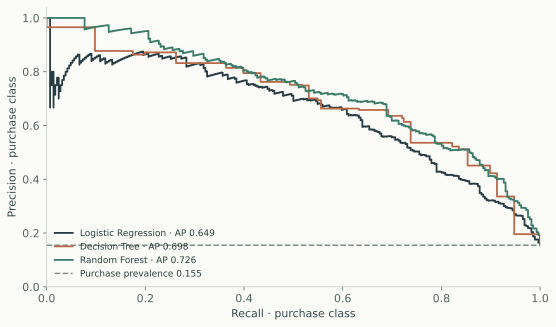

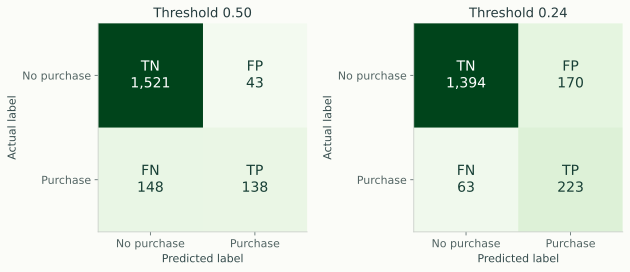

In [4]:
test = pd.read_csv(ROOT / 'results/test_metrics.csv')
display(test)
official = test[(test.model == selection['selected_model']) & (test.feature_set == 'full') & (test.threshold == selection['threshold'])].iloc[0]
print(f"Selected {selection['selected_model']}; test AP {official.ap:.6f}; F1 {official.f1:.6f}; recall {official.recall:.6f}.")
print(f"Detected {int(official.tp)} / {int(official.purchases)} buyers; false alarms {int(official.fp)} / {int(official.support-official.purchases)} non-buyers.")
display(SVG(filename=str(ROOT / 'results/figures/precision_recall.svg')))
display(SVG(filename=str(ROOT / 'results/figures/confusion.svg')))

## Tree capacity diagnostic
Keep min_samples_leaf=5 and threshold=0.50 fixed. Compare training and validation F1 at several depths; this diagnostic did not replace the declared model selection rule.

,max_depth,partition,threshold,support,purchases,predicted_purchases,precision,recall,f1,ap,roc_auc,accuracy,tn,fp,fn,tp,precision_defined,recall_defined
0,3,train,0.5,8630,1336,1211,0.694467,0.629491,0.660385,0.664180,0.908228,0.899768,6924,370,495,841,True,True
1,3,validation,0.5,1850,286,232,0.711207,0.576923,0.637066,0.631548,0.900795,0.898378,1497,67,121,165,True,True
2,5,train,0.5,8630,1336,990,0.787879,0.583832,0.670679,0.752816,0.931512,0.911240,7084,210,556,780,True,True
3,5,validation,0.5,1850,286,199,0.728643,0.506993,0.597938,0.671725,0.912261,0.894595,1510,54,141,145,True,True
4,8,train,0.5,8630,1336,1107,0.823848,0.682635,0.746623,0.846301,0.959670,0.928273,7099,195,424,912,True,True
5,8,validation,0.5,1850,286,223,0.663677,0.517483,0.581532,0.641565,0.878378,0.884865,1489,75,138,148,True,True
6,12,train,0.5,8630,1336,1252,0.849840,0.796407,0.822257,0.918511,0.981721,0.946698,7106,188,272,1064,True,True
7,12,validation,0.5,1850,286,253,0.620553,0.548951,0.582560,0.551289,0.811798,0.878378,1468,96,129,157,True,True
8,unbounded,train,0.5,8630,1336,1303,0.845741,0.824850,0.835165,0.932820,0.987235,0.949594,7093,201,234,1102,True,True
9,unbounded,validation,0.5,1850,286,268,0.597015,0.559441,0.577617,0.536144,0.810088,0.873514,1456,108,126,160,True,True


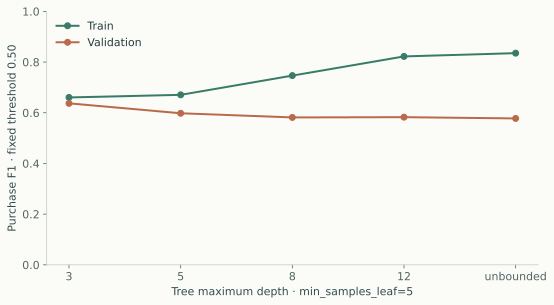

In [5]:
display(pd.read_csv(ROOT / 'results/tree_depth_comparison.csv'))
display(SVG(filename=str(ROOT / 'results/figures/tree_depth.svg')))

## PageValues sensitivity
LR and RF are independently retrained without PageValues, on the same rows and original small grids. Inspect validation dependence before freezing, then report prespecified test variants. Full features stay primary; removal is not proof of leakage or of real-time availability.

,model,feature_set,partition,threshold,support,purchases,predicted_purchases,precision,recall,f1,ap,roc_auc,accuracy,tn,fp,fn,tp,precision_defined,recall_defined
0,Logistic Regression,full,validation,0.5,1850,286,139,0.733813,0.356643,0.480000,0.648512,0.893956,0.880541,1527,37,184,102,True,True
1,Random Forest,full,validation,0.5,1850,286,170,0.794118,0.472028,0.592105,0.725437,0.919804,0.899459,1529,35,151,135,True,True
2,Logistic Regression,no_PageValues,validation,0.5,1850,286,14,0.428571,0.020979,0.040000,0.313313,0.756336,0.844324,1556,8,280,6,True,True
3,Random Forest,no_PageValues,validation,0.5,1850,286,26,0.730769,0.066434,0.121795,0.376621,0.759886,0.851892,1557,7,267,19,True,True
4,Logistic Regression,full,test,0.5,1850,286,134,0.783582,0.367133,0.500000,0.649399,0.890309,0.886486,1535,29,181,105,True,True
5,Random Forest,full,test,0.5,1850,286,181,0.762431,0.482517,0.591006,0.725975,0.919464,0.896757,1521,43,148,138,True,True
6,Logistic Regression,no_PageValues,test,0.5,1850,286,14,0.500000,0.024476,0.046667,0.344051,0.753662,0.845405,1557,7,279,7,True,True
7,Random Forest,no_PageValues,test,0.5,1850,286,36,0.555556,0.069930,0.124224,0.354664,0.752808,0.847568,1548,16,266,20,True,True


Logistic Regression: validation AP 0.649 → 0.313 (change -0.335); test AP 0.649 → 0.344 (change -0.305). Random Forest: validation AP 0.725 → 0.377 (change -0.349); test AP 0.726 → 0.355 (change -0.371). This measures dependence on PageValues, not proof of target leakage. Removing it also does not establish real-time availability of the remaining session summaries.


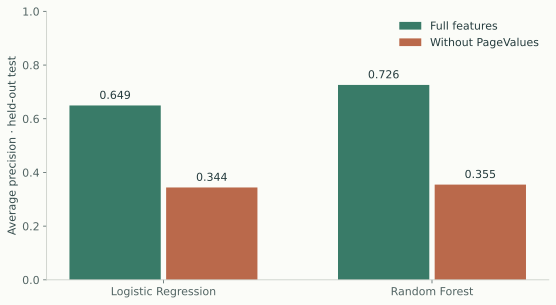

In [6]:
comparison = pd.read_csv(ROOT / 'results/pagevalues_comparison.csv')
display(comparison)
from src.report import sensitivity_text
print(sensitivity_text({'validation_metrics': validation.to_dict('records'), 'test_metrics': test.to_dict('records')}))
display(SVG(filename=str(ROOT / 'results/figures/pagevalues.svg')))

## Mistakes and denominators
FP means a predicted buyer did not purchase; FN means a real buyer was missed. The first four source-row IDs per category are shown deterministically. ProductRelated bins use training tertiles. Small subgroup support precludes strong conclusions.

In [7]:
errors = saved('error_analysis.json')
display(pd.Series(errors['bin_boundaries']))
display(pd.DataFrame(errors['subgroups']))
for kind, examples in errors['examples'].items():
    print(kind)
    display(pd.DataFrame(examples))

low                        ProductRelated <= 10
medium                10 < ProductRelated <= 29
high                        ProductRelated > 29
training_quantiles                 [10.0, 29.0]
dtype: object

,grouping,group,threshold,support,purchases,predicted_purchases,precision,recall,f1,ap,roc_auc,accuracy,tn,fp,fn,tp,precision_defined,recall_defined
0,VisitorType,New_Visitor,0.24,265,69,64,0.828125,0.768116,0.796992,0.865246,0.901582,0.898113,185,11,16,53,True,True
1,VisitorType,Other,0.24,11,3,3,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,8,0,0,3,True,True
2,VisitorType,Returning_Visitor,0.24,1574,214,326,0.512270,0.780374,0.618519,0.638788,0.916262,0.869123,1201,159,47,167,True,True
3,ProductRelated_bin,low,0.24,622,39,28,0.714286,0.512821,0.597015,0.630953,0.924220,0.956592,575,8,19,20,True,True
4,ProductRelated_bin,medium,0.24,633,107,133,0.661654,0.822430,0.733333,0.807442,0.937422,0.898894,481,45,19,88,True,True
5,ProductRelated_bin,high,0.24,595,140,232,0.495690,0.821429,0.618280,0.668532,0.865432,0.761345,338,117,25,115,True,True


FP


,source_row_id,VisitorType,ProductRelated,ProductRelated_Duration,PageValues,Revenue,purchase_score,predicted_label
0,384,Returning_Visitor,61,2258.430586,2.810812,0,0.383246,1
1,857,Returning_Visitor,27,520.333333,8.497935,0,0.577144,1
2,894,Returning_Visitor,38,1054.944444,8.224169,0,0.403394,1
3,1026,Returning_Visitor,83,1778.125214,6.626648,0,0.321572,1


FN


,source_row_id,VisitorType,ProductRelated,ProductRelated_Duration,PageValues,Revenue,purchase_score,predicted_label
0,2746,Returning_Visitor,62,3657.101515,9.027321,1,0.180422,0
1,4407,Returning_Visitor,19,421.600000,6.624947,1,0.206613,0
2,4632,Returning_Visitor,38,1155.000000,5.903182,1,0.183728,0
3,5593,Returning_Visitor,5,136.100000,0.000000,1,0.078981,0


## Duplicate sensitivity
This separate group-aware split keeps identical predictor vectors together. It reuses the primary selected model parameters and threshold without group-test selection. Different rows and supports make it a sensitivity check rather than a replacement for the primary result.

In [8]:
display(pd.read_csv(ROOT / 'results/group_sensitivity.csv'))
display(pd.Series(saved('run.json')))

,model,feature_set,partition,threshold,support,purchases,predicted_purchases,precision,recall,f1,ap,roc_auc,accuracy,tn,fp,fn,tp,precision_defined,recall_defined
0,Random Forest,full,group_validation,0.24,1848,285,383,0.592689,0.796491,0.679641,0.762834,0.933311,0.884199,1407,156,58,227,True,True
1,Random Forest,full,group_test,0.24,1850,287,391,0.595908,0.811847,0.687316,0.751015,0.929698,0.885405,1405,158,54,233,True,True


run_id                                                          ss-b3055ee3-c246965f
data_sha256                        b3055ee355f59134d851d32641183cb4a8b45def7124d2...
source_code_sha256                 c246965fe7350298c94c4ebe0ea2a6ab9fe0609e401999...
training_and_evaluation_seconds                                           232.948805
test_policy                                 No test-based model or threshold changes
environment                        {'python': '3.12.14', 'numpy': '2.5.5', 'panda...
dtype: object

## A meaningful validation interaction
The site exports exact validation labels/scores in row-ID order. Rule: score >= threshold. Changing the slider changes counts only; no retraining and no official test changes. The JS/Python parity check also covers equality, endpoint thresholds and zero positives.

In [9]:
web = json.loads((ROOT / 'docs/data/threshold_validation.json').read_text())
assert web['partition'] == 'validation'
display(pd.DataFrame([{'threshold': t, **metrics(web['y_true'], web['purchase_score'], t)} for t in [0., .5, 1., selection['threshold']]]))

,threshold,support,purchases,predicted_purchases,precision,recall,f1,ap,roc_auc,accuracy,tn,fp,fn,tp,precision_defined,recall_defined
0,0.00,1850,286,1850,0.154595,1.000000,0.267790,0.725437,0.919804,0.154595,0,1564,0,286,True,True
1,0.50,1850,286,170,0.794118,0.472028,0.592105,0.725437,0.919804,0.899459,1529,35,151,135,True,True
2,1.00,1850,286,0,0.000000,0.000000,0.000000,0.725437,0.919804,0.845405,1564,0,286,0,False,True
3,0.24,1850,286,371,0.587601,0.762238,0.663623,0.725437,0.919804,0.880541,1411,153,68,218,True,True


## Conclusion and disclosure
Session summaries contain predictive signal beyond a majority baseline, but there are missed purchases and dependence on PageValues. One random historical split does not validate future shops, early-session intervention, causal uplift, preferences or calibration. No statistical significance or confidence interval is claimed.

We developed ShopperSense as a course project to explore how browsing behaviour relates to online purchase intent. We used AI tools, including ChatGPT and Codex, to assist with planning, coding, debugging, documentation, and website development. AI-generated code and suggestions supported the project. Human verification has been completed, and I have a complete understanding of the project. Responsibility for the submitted work, its interpretation, and its limitations remains mine. Sources: UCI [doi:10.24432/C5F88Q](https://doi.org/10.24432/C5F88Q), [scikit-learn metric documentation](https://scikit-learn.org/stable/modules/model_evaluation.html).